# 07 — Comparação pareada com as reservas informadas à gestora

A gestora recebe na sexta-feira, por e-mail, a quantidade prevista para cada almoço de segunda a sexta da semana seguinte. Este notebook compara cada método e o baseline de reservas nas mesmas datas, com a mesma origem semanal. Ausência de reserva não é zero. O consumo observado é alvo de avaliação; excesso e falta calculados contra ele são potenciais e não medem sobra real nem refeição não atendida.

A análise usa somente 2023–2025. Cada origem precisa ser sexta-feira e cada alvo, um dia útil da semana seguinte.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "gold").is_dir()), None)
if ROOT is None: raise RuntimeError("Não localizei a raiz do projeto.")
LINE_ID = "consumo_cardapio_calendario"
LINE_RESULTS = ROOT / "resultados" / "linhas" / LINE_ID
PREDICTIONS = LINE_RESULTS / "05_ablation_grupos_features" / "previsoes_ablation_completo_baselines.csv"
RESERVATIONS = ROOT / "data" / "silver" / "reservas" / "reservas_diario_2023_2026.csv"
GOLD = ROOT / "data" / "gold" / "base_modelagem_consumo_cardapio_calendario_v0.csv"
OUT = LINE_RESULTS / "07_comparacao_reservas"
OUT.mkdir(parents=True, exist_ok=True)
for p in [PREDICTIONS, RESERVATIONS, GOLD]:
    if not p.exists(): raise FileNotFoundError(p)


In [2]:
pred = pd.read_csv(PREDICTIONS, encoding="utf-8-sig", low_memory=False)
required = {"data", "origem", "fold", "consumo_real", "previsao", "condicao", "modelo_original"}
missing = required - set(pred.columns)
if missing: raise KeyError(f"Colunas ausentes nas previsões: {sorted(missing)}")
pred["data"] = pd.to_datetime(pred["data"], format="mixed", errors="raise").dt.normalize()
pred["origem"] = pd.to_datetime(pred["origem"], format="mixed", errors="raise").dt.normalize()
pred["consumo_real"] = pd.to_numeric(pred["consumo_real"], errors="raise")
pred["previsao"] = pd.to_numeric(pred["previsao"], errors="raise")
pred["fold"] = pd.to_numeric(pred["fold"], errors="raise").astype(int)
pred = pred[pred.data.dt.year.between(2023,2025) & pred.data.dt.dayofweek.lt(5)].copy()
pred["origem_esperada"]=(pred.data-pd.to_timedelta(pred.data.dt.dayofweek,unit="D")-pd.Timedelta(days=3)).dt.normalize()
assert pred.origem.eq(pred.origem_esperada).all(), "Origem não é a sexta-feira anterior à semana-alvo."
reservas=pd.read_csv(RESERVATIONS,encoding="utf-8-sig",parse_dates=["data"])
reservas=reservas.loc[reservas.data.dt.year.between(2023,2025) & reservas.status_reservas.eq("observado") & reservas.reservas.notna(),["data","reservas"]].copy()
reservas["data"]=reservas.data.dt.normalize()
assert not reservas.data.duplicated().any(), "Reserva diária duplicada."
pred=pred.merge(reservas,on="data",how="inner",validate="many_to_one")
gold=pd.read_csv(GOLD,encoding="utf-8-sig",parse_dates=["data"])[["data","consumo_total"]]
gold["data"]=gold.data.dt.normalize();gold=gold[gold.data.dt.year.between(2023,2025)]
pred=pred.merge(gold,on="data",how="left",validate="many_to_one")
assert pred.consumo_total.notna().all() and np.allclose(pred.consumo_real,pred.consumo_total), "Alvo previsto diverge do consumo Gold."
pred["metodo"] = pred["condicao"].astype(str) + "::" + pred["modelo_original"].astype(str)
assert np.isfinite(pred[["consumo_real", "previsao"]].to_numpy()).all()
date_sets = pred.groupby("metodo").data.apply(lambda s: set(s.unique()))
reservation_dates = set(reservas.data)
common_dates = set.intersection(*date_sets.tolist(), reservation_dates) if len(date_sets) else set()
assert common_dates, "Não há datas comuns entre os métodos e as reservas observadas."
model_pairs = pred[pred.data.isin(common_dates)].copy()
model_pairs["familia"] = model_pairs.get("familia", "modelo")
model_pairs["ano"] = model_pairs.data.dt.year
model_pairs["previsao_inteira"] = np.maximum(0, np.ceil(model_pairs.previsao))
model_pairs["quantidade_planejada"] = model_pairs.previsao_inteira.astype(int)
model_pairs["plano"] = model_pairs.quantidade_planejada
model_pairs["reservas"] = model_pairs.reservas.astype(float)
model_pairs["tipo"] = "modelo"
model_pairs["erro_abs_modelo"] = (model_pairs.previsao_inteira-model_pairs.consumo_real).abs()
model_pairs["erro_abs_reserva"] = (model_pairs.reservas-model_pairs.consumo_real).abs()
model_pairs["erro_modelo"] = model_pairs.previsao_inteira-model_pairs.consumo_real
model_pairs["excesso_potencial_modelo"] = (model_pairs.previsao_inteira-model_pairs.consumo_real).clip(lower=0)
model_pairs["falta_potencial_modelo"] = (model_pairs.consumo_real-model_pairs.previsao_inteira).clip(lower=0)
model_pairs["reserva_inteira"] = np.maximum(0, np.rint(model_pairs.reservas))
model_pairs["excesso_potencial_reserva"] = (model_pairs.reserva_inteira-model_pairs.consumo_real).clip(lower=0)
model_pairs["falta_potencial_reserva"] = (model_pairs.consumo_real-model_pairs.reserva_inteira).clip(lower=0)

cohort_meta=model_pairs[["data","origem","fold","consumo_real"]].drop_duplicates("data")
reserve_pairs=cohort_meta.merge(reservas[["data","reservas"]],on="data",how="inner",validate="one_to_one")
reserve_pairs["ano"]=reserve_pairs.data.dt.year
reserve_pairs["metodo"]="Baseline_Reservas::total_reservas_observado"
reserve_pairs["modelo_original"]="total_reservas_observado"
reserve_pairs["condicao"]="Baseline_Reservas"
reserve_pairs["familia"]="baseline_reservas"
reserve_pairs["tipo"]="baseline"
reserve_pairs["previsao"]=reserve_pairs.reservas
reserve_pairs["reserva_inteira"]=np.maximum(0,np.rint(reserve_pairs.reservas))
reserve_pairs["quantidade_planejada"]=reserve_pairs.reserva_inteira.astype(int)
reserve_pairs["plano"]=reserve_pairs.quantidade_planejada
reserve_pairs["previsao_inteira"]=reserve_pairs.quantidade_planejada
reserve_pairs["erro_abs_modelo"]=(reserve_pairs.previsao-reserve_pairs.consumo_real).abs()
reserve_pairs["erro_abs_reserva"]=reserve_pairs.erro_abs_modelo
reserve_pairs["erro_modelo"]=reserve_pairs.previsao-reserve_pairs.consumo_real
reserve_pairs["excesso_potencial_modelo"]=(reserve_pairs.previsao-reserve_pairs.consumo_real).clip(lower=0)
reserve_pairs["falta_potencial_modelo"]=(reserve_pairs.consumo_real-reserve_pairs.previsao).clip(lower=0)
reserve_pairs["excesso_potencial_reserva"]=reserve_pairs.excesso_potencial_modelo
reserve_pairs["falta_potencial_reserva"]=reserve_pairs.falta_potencial_modelo
paired=pd.concat([model_pairs, reserve_pairs],ignore_index=True,sort=False)
assert paired.groupby("metodo").data.nunique().eq(len(common_dates)).all()

def metrics(g,prediction):
    err=g[prediction]-g.consumo_real
    total=g.consumo_real.sum()
    return {"n_datas":len(g),"MAE":float(err.abs().mean()),"WAPE_pct":float(err.abs().sum()/total*100) if total else np.nan,"vies":float(err.mean()),"excesso_potencial":float((g[prediction]-g.consumo_real).clip(lower=0).sum()),"falta_potencial":float((g.consumo_real-g[prediction]).clip(lower=0).sum()),"dias_com_falta_potencial":int((g[prediction]<g.consumo_real).sum())}
records=[]
for method,g in model_pairs.groupby("metodo"):
    m=metrics(g,"previsao_inteira")
    m.update({"metodo":method,"tipo":"modelo","coorte":"comum a todos os métodos e reservas"})
    records.append(m)
m=metrics(reserve_pairs,"reserva_inteira");m.update({"metodo":"Reservas informadas à gestora","tipo":"baseline","coorte":"comum a todos os métodos e reservas"});records.append(m)
metrics_common=pd.DataFrame(records).sort_values("MAE")
records_ind=[]
for method,g in model_pairs.groupby("metodo"):
    mm=metrics(g,"previsao_inteira");rr=metrics(g,"reserva_inteira")
    records_ind.append({"metodo":method,"n_datas":mm["n_datas"],"MAE_modelo":mm["MAE"],"MAE_reserva_mesmas_datas":rr["MAE"],"WAPE_modelo_pct":mm["WAPE_pct"],"WAPE_reserva_mesmas_datas_pct":rr["WAPE_pct"],"vies_modelo":mm["vies"],"falta_potencial_modelo":mm["falta_potencial"],"excesso_potencial_modelo":mm["excesso_potencial"]})
metrics_each=pd.DataFrame(records_ind).sort_values("MAE_modelo")
paired.to_csv(OUT/"previsoes_pareadas.csv",index=False,encoding="utf-8-sig")
metrics_common.to_csv(OUT/"metricas_coorte_comum.csv",index=False,encoding="utf-8-sig")
metrics_each.to_csv(OUT/"metricas_pareadas_por_metodo.csv",index=False,encoding="utf-8-sig")
audit=pd.DataFrame([{"datas_com_previsao":pred.data.nunique(),"datas_com_reserva_observada":reservas.data.nunique(),"datas_pareadas_por_metodo":model_pairs.data.nunique(),"datas_comuns_a_todos_metodos_e_reservas":len(common_dates),"metodos_modelo":model_pairs.metodo.nunique(),"origens_semanais":model_pairs.origem.nunique(),"reserva_ausente_nunca_imputada_com_zero":True}])
audit.to_csv(OUT/"auditoria_coorte.csv",index=False,encoding="utf-8-sig")
display(audit);display(metrics_common.round(2));display(metrics_each.head(12).round(2))

,datas_com_previsao,datas_com_reserva_observada,datas_pareadas_por_metodo,datas_comuns_a_todos_metodos_e_reservas,metodos_modelo,origens_semanais,reserva_ausente_nunca_imputada_com_zero
0,397,510,390,390,65,91,True


,n_datas,MAE,WAPE_pct,vies,excesso_potencial,falta_potencial,dias_com_falta_potencial,metodo,tipo,coorte
42,390,22.89,16.58,2.31,4915.0,4013.0,192,Historico_Calendario::ExtraTrees,modelo,comum a todos os métodos e reservas
40,390,22.93,16.60,1.38,4739.0,4202.0,206,Historico_Calendario::Ensemble_top5_validacao_...,modelo,comum a todos os métodos e reservas
39,390,22.93,16.61,1.39,4742.0,4201.0,207,Historico_Calendario::Ensemble_top5_ponderado_...,modelo,comum a todos os métodos e reservas
55,390,22.96,16.63,0.65,4605.0,4351.0,204,Historico_Cardapio::Ensemble_top3_validacao_media,modelo,comum a todos os métodos e reservas
56,390,22.97,16.63,0.27,4532.0,4425.0,203,Historico_Cardapio::Ensemble_top5_ponderado_va...,modelo,comum a todos os métodos e reservas
...,...,...,...,...,...,...,...,...,...,...
27,390,34.22,24.78,9.69,8563.0,4784.0,182,Historico::MLP,modelo,comum a todos os métodos e reservas
28,390,41.14,29.79,6.97,9383.0,6663.0,206,Historico::Prophet,modelo,comum a todos os métodos e reservas
62,390,42.93,31.09,6.86,9708.0,7034.0,199,Historico_Cardapio::Prophet,modelo,comum a todos os métodos e reservas
11,390,44.28,32.06,6.89,9977.0,7291.0,199,Completo_Notebook04::Prophet,modelo,comum a todos os métodos e reservas


,metodo,n_datas,MAE_modelo,MAE_reserva_mesmas_datas,WAPE_modelo_pct,WAPE_reserva_mesmas_datas_pct,vies_modelo,falta_potencial_modelo,excesso_potencial_modelo
42,Historico_Calendario::ExtraTrees,390,22.89,28.66,16.58,20.76,2.31,4013.0,4915.0
40,Historico_Calendario::Ensemble_top5_validacao_...,390,22.93,28.66,16.60,20.76,1.38,4202.0,4739.0
39,Historico_Calendario::Ensemble_top5_ponderado_...,390,22.93,28.66,16.61,20.76,1.39,4201.0,4742.0
55,Historico_Cardapio::Ensemble_top3_validacao_media,390,22.96,28.66,16.63,20.76,0.65,4351.0,4605.0
56,Historico_Cardapio::Ensemble_top5_ponderado_va...,390,22.97,28.66,16.63,20.76,0.27,4425.0,4532.0
57,Historico_Cardapio::Ensemble_top5_validacao_media,390,22.98,28.66,16.64,20.76,0.28,4427.0,4535.0
24,Historico::Ensemble_top5_validacao_mediana,390,23.03,28.66,16.67,20.76,0.20,4451.0,4529.0
58,Historico_Cardapio::Ensemble_top5_validacao_me...,390,23.03,28.66,16.68,20.76,0.12,4468.0,4513.0
15,Historico::CatBoost_native,390,23.08,28.66,16.71,20.76,-0.08,4516.0,4485.0
5,Completo_Notebook04::CatBoost_native,390,23.08,28.66,16.71,20.76,-0.67,4631.0,4370.0


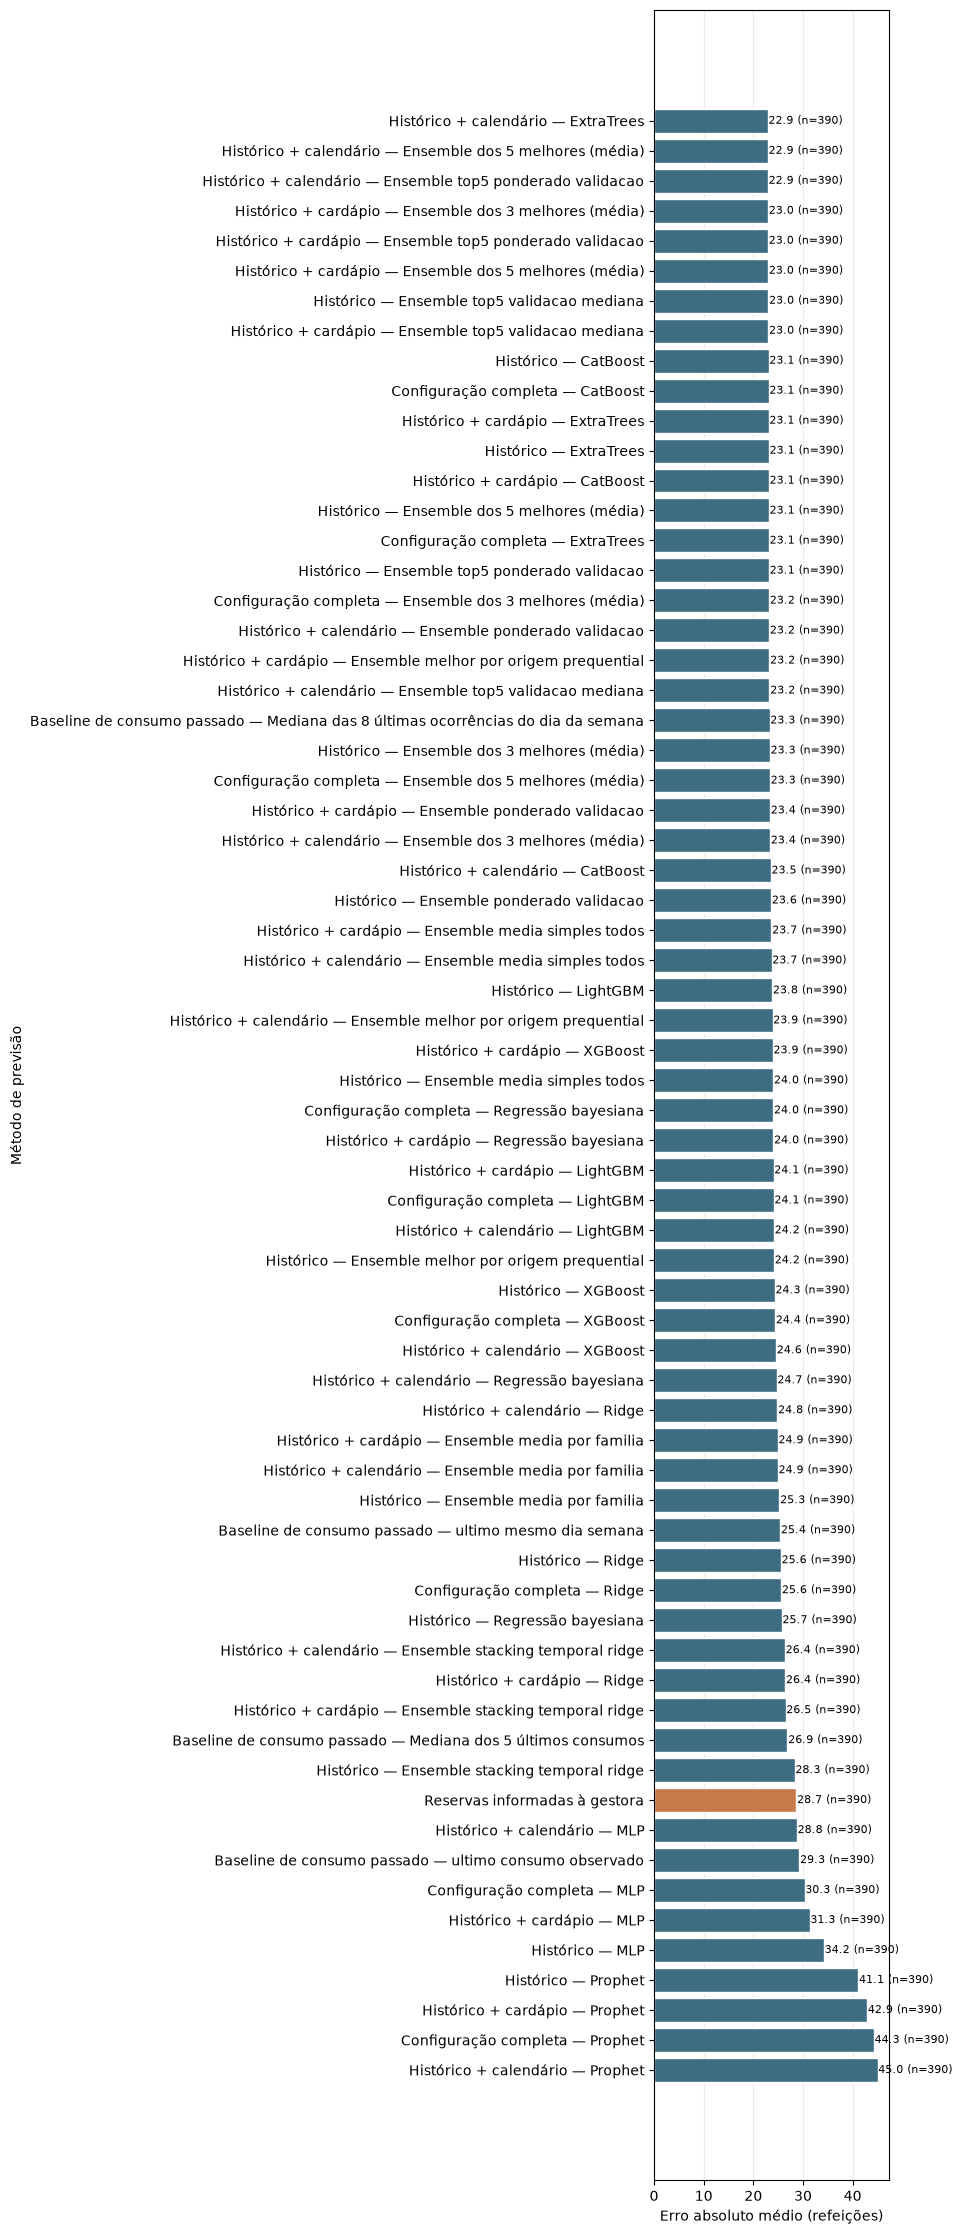

**Leitura:** a coorte comum contém 390 datas, provenientes de 91 origens semanais. A figura compara erros de previsão nas mesmas datas. Excesso e falta são calculados em relação ao consumo observado e representam potencial; sem dados de produção e atendimento, não equivalem a desperdício ou demanda não atendida.

In [3]:
plot=metrics_common.sort_values("MAE",ascending=True).copy()
cond_pt={"Baseline_Reservas":"Reservas informadas à gestora","Baseline_Notebook03":"Baseline de consumo passado","Completo_Notebook04":"Configuração completa","Historico":"Histórico","Historico_Calendario":"Histórico + calendário","Historico_Cardapio":"Histórico + cardápio","Atual_sem_reserva_clima":"Referência sem reservas e clima","Atual_mais_reservas":"Referência + reservas","Atual_mais_clima":"Referência + clima","Atual_mais_reservas_clima":"Referência + reservas e clima"}
model_pt={"Ensemble_top3_validacao_media":"Ensemble dos 3 melhores (média)","Ensemble_top5_validacao_media":"Ensemble dos 5 melhores (média)","BayesianRidge":"Regressão bayesiana","CatBoost_native":"CatBoost","LinearRegression":"Regressão linear","mediana_ultimos_5_consumos":"Mediana dos 5 últimos consumos","mediana_ultimos_8_mesmo_dia_semana":"Mediana das 8 últimas ocorrências do dia da semana"}
def label_pt(method):
    parts = str(method).split("::", 1)
    if len(parts) == 1:
        return parts[0].replace("_", " ")
    condition, model = parts
    return cond_pt.get(condition, condition.replace("_", " ")) + " — " + model_pt.get(model, model.replace("_", " "))
plot["rotulo"] = plot.metodo.map(label_pt)
fig,ax=plt.subplots(figsize=(9.5,max(5.5,.34*len(plot))))
colors=["#C8794B" if t=="baseline" else "#3E6C83" for t in plot.tipo]
bars=ax.barh(plot.rotulo,plot.MAE,color=colors,edgecolor="white")
for b,n in zip(bars,plot.n_datas): ax.text(b.get_width()+.15,b.get_y()+b.get_height()/2,f"{b.get_width():.1f} (n={int(n)})",va="center",fontsize=8)
ax.set_xlabel("Erro absoluto médio (refeições)"); ax.set_ylabel("Método de previsão")
ax.grid(axis="x",alpha=.25); ax.set_axisbelow(True); ax.invert_yaxis()
fig.tight_layout(); fig.savefig(OUT/"mae_modelos_vs_reservas.png",dpi=300,bbox_inches="tight"); fig.savefig(OUT/"mae_modelos_vs_reservas.pdf",bbox_inches="tight"); plt.show()
display(Markdown(f"**Leitura:** a coorte comum contém {len(common_dates)} datas, provenientes de {paired.origem.nunique()} origens semanais. A figura compara erros de previsão nas mesmas datas. Excesso e falta são calculados em relação ao consumo observado e representam potencial; sem dados de produção e atendimento, não equivalem a desperdício ou demanda não atendida."))